# d2 · Student architecture: how small can a model trained on the data alone get?

Starting point from the c-notebooks: the teacher's layout (5 conv layers, BatchNorm, average pooling, 4 stages
that halve the resolution, global average pooling) and its training recipe. c7 showed 5x5 kernels beat 3x3, but
d1 showed the cost of a conv grows with kernel area and the square of the width. So the students vary the three
levers that set the size:

| lever | options |
|---|---|
| width (first stage; the others double) | 32, **16 (teacher)**, 8, 4, 2 |
| kernel | **5x5 (teacher)**, 3x3 |
| block | **plain conv (teacher)**, depthwise-separable (depthwise k x k + pointwise 1x1) |

15 students, 3 seeds each, trained on the labels only (no teacher). Distillation is d3. The teacher's own
architecture is the c9 runs (no retraining).

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from lib import compress as C, dreport as R
from lib.train import RESULTS, build_model
from lib.data import ARTIFACTS
W = lambda w0: (w0, 2 * w0, 4 * w0, 8 * w0)
GRID = {("single", 5): [8, 4, 2], ("single", 3): [16, 8, 4, 2],
        ("dwsep", 5): [32, 16, 8, 4, 2], ("dwsep", 3): [16, 8, 4]}
runs = {}
for (block, k), ws in GRID.items():
    for w0 in ws:
        cfg = R.student("d2", f"{block}_k{k}_w{w0}", block=block, kernel=k, stem_kernel=k, widths=W(w0))
        runs[(block, k, w0)] = R.run_seeds(cfg)
# the teacher's architecture trained on the data = the c9 runs (same recipe); sizes from the architecture
tsize = C.size_report(build_model(R.teacher_cfg(), 1))
runs[("single", 5, 16)] = [dict(json.loads((RESULTS / "c9" / f"final_s{s}.json").read_text()), size=tsize) for s in R.SEEDS3]
print(len(runs), "architectures,", sum(len(v) for v in runs.values()), "runs")

16 architectures, 48 runs


## 1. Every student

In [2]:
fam = lambda b, k: f"{'plain' if b == 'single' else 'depthwise-sep.'} {k}x{k}"
t = R.table({f"{fam(b, k)}, w{w0}": rs for (b, k, w0), rs in runs.items()})
t["family"] = [fam(b, k) for (b, k, w0) in runs]; t["width"] = [w0 for (b, k, w0) in runs]
t = t.sort_values("bytes")
display(t[["family", "width", "params", "kB", "x smaller than teacher", "bal_acc", "sd", "tumor_auc", "no_tumor_rec"]])

,family,width,params,kB,x smaller than teacher,bal_acc,sd,tumor_auc,no_tumor_rec
"depthwise-sep. 5x5, w2",depthwise-sep. 5x5,2,786,2.8828,374.4878,0.7946,0.0248,0.9675,0.8541
"depthwise-sep. 3x3, w4",depthwise-sep. 3x3,4,1336,4.8438,222.8806,0.8370,0.0172,0.9789,0.8681
"plain 3x3, w2",plain 3x3,2,1698,6.5078,165.8896,0.8301,0.0535,0.9783,0.8438
"depthwise-sep. 5x5, w4",depthwise-sep. 5x5,4,1912,7.0938,152.1872,0.8616,0.0049,0.9818,0.8820
"depthwise-sep. 3x3, w8",depthwise-sep. 3x3,8,4044,15.0469,71.7477,0.8906,0.0148,0.9873,0.8993
"plain 5x5, w2",plain 5x5,2,4482,17.3828,62.1061,0.8660,0.0146,0.9859,0.9097
"depthwise-sep. 5x5, w8",depthwise-sep. 5x5,8,5196,19.5469,55.2302,0.9158,0.0062,0.9894,0.9132
"plain 3x3, w4",plain 3x3,4,6488,25.0938,43.0218,0.9063,0.0135,0.9892,0.8958
"depthwise-sep. 3x3, w16",depthwise-sep. 3x3,16,13588,51.5781,20.9309,0.9484,0.0045,0.9969,0.9549
"depthwise-sep. 5x5, w16",depthwise-sep. 5x5,16,15892,60.5781,17.8213,0.9415,0.0018,0.9934,0.9340


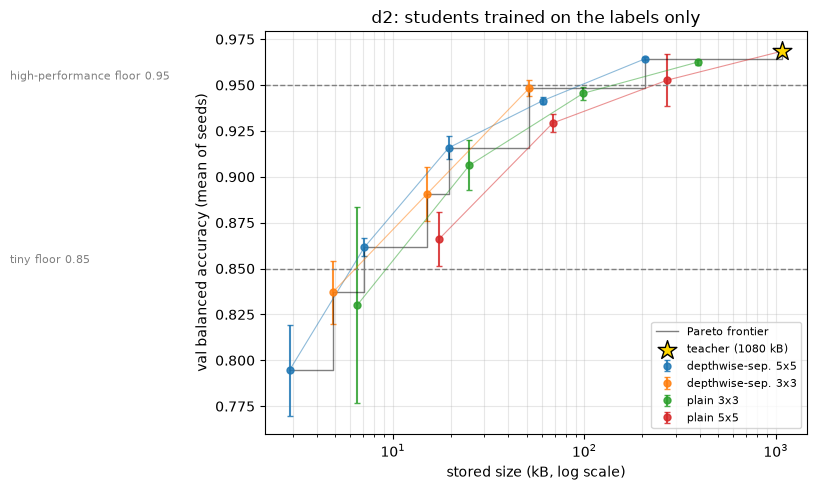

In [3]:
groups = {f: t[t.family == f] for f in t.family.unique()}
ax = R.tradeoff_plot(groups, "d2: students trained on the labels only", teacher_acc=float(t.loc["plain 5x5, w16", "bal_acc"]))
for i, g in enumerate(groups.values()):   # connect each family's widths (same colours as the points)
    g = g.sort_values("bytes"); ax.plot(g.kB.astype(float), g.bal_acc.astype(float), "-", lw=0.8, alpha=0.5, color=f"C{i}")
plt.tight_layout(); plt.show()

**Result.** 16 architectures from 1,080 kB (the teacher's own layout) down to 2.9 kB, all trained on the labels
with the teacher's recipe.

* **Accuracy falls slowly at first, then fast.** Down to about 200 kB nothing is lost (depthwise-separable 5x5,
  width 32: 0.964, teacher layout 0.969). From there each halving of the width costs more: 0.948 at 52 kB,
  0.916 at 20 kB, 0.862 at 7 kB, 0.795 at 2.9 kB.
* **Depthwise-separable blocks win at every size.** At about the same size they beat a plain conv clearly:
  dw-sep 5x5 w32 0.964 at 207 kB vs plain 5x5 w8 0.953 at 271 kB; dw-sep 3x3 w16 0.948 at 52 kB vs plain 3x3 w4
  0.906 at 25 kB and plain 5x5 w4 0.929 at 68 kB. Splitting a k x k conv into a per-channel k x k filter and a 1x1
  channel mixer costs k²·c + c·c' weights instead of k²·c·c', and for these images that loses little.
* **Kernel size** matters less than the block type. Within depthwise-separable, 3x3 and 5x5 trade places
  (3x3 better at width 16, 5x5 better at width 4 and 8). In depthwise-separable blocks a 5x5 kernel is cheap
  (the k² term is per channel, not per channel pair), so the c7 finding (5x5 better) carries over at small widths.
* **Seed spread grows as models shrink** (sd up to 0.05 for plain 3x3 w2): tiny models are less stable.
* The no_tumor class suffers first (recall 0.85 at 2.9 kB vs 0.97 for the teacher layout, 3-seed means): the smallest models confuse it
  with the tumour classes more often.

## 2. The frontier

In [4]:
F = R.pareto(t)
display(F[["family", "width", "params", "kB", "x smaller than teacher", "bal_acc", "sd"]])
for name, fl in R.FLOORS.items():
    k = R.pick(t, fl); print(f"smallest >= {fl} ({name}):", k, "" if k is None else f"{t.loc[k, 'kB']:.1f} kB, {t.loc[k, 'bal_acc']:.4f}")
_ = (ARTIFACTS / "d2_frontier.json").write_text(json.dumps(
    [{"name": f"{b}_k{k}_w{w0}", "block": b, "kernel": k, "w0": w0} for (b, k, w0) in runs if f"{fam(b, k)}, w{w0}" in F.index]))

,family,width,params,kB,x smaller than teacher,bal_acc,sd
"depthwise-sep. 5x5, w2",depthwise-sep. 5x5,2,786,2.8828,374.4878,0.7946,0.0248
"depthwise-sep. 3x3, w4",depthwise-sep. 3x3,4,1336,4.8438,222.8806,0.8370,0.0172
"depthwise-sep. 5x5, w4",depthwise-sep. 5x5,4,1912,7.0938,152.1872,0.8616,0.0049
"depthwise-sep. 3x3, w8",depthwise-sep. 3x3,8,4044,15.0469,71.7477,0.8906,0.0148
"depthwise-sep. 5x5, w8",depthwise-sep. 5x5,8,5196,19.5469,55.2302,0.9158,0.0062
"depthwise-sep. 3x3, w16",depthwise-sep. 3x3,16,13588,51.5781,20.9309,0.9484,0.0045
"depthwise-sep. 5x5, w32",depthwise-sep. 5x5,32,53796,207.1406,5.2118,0.9643,0.0009
"plain 5x5, w16",plain 5x5,16,276628,1079.5781,1.0000,0.9685,0.0008


smallest >= 0.95 (high-performance): depthwise-sep. 5x5, w32 207.1 kB, 0.9643
smallest >= 0.85 (tiny): depthwise-sep. 5x5, w4 7.1 kB, 0.8616


**Frontier.** Every model on it below the teacher's size is depthwise-separable (5x5 or 3x3, alternating).
Plain convs only appear at the top (the teacher's own layout, 0.969 at 1,080 kB), which is 5x larger than the
depthwise-separable w32 student for 0.4 pp.

**Floors, labels only:** the smallest model at or above 0.85 is depthwise-separable 5x5 w4 (7.1 kB, 0.862,
152x smaller than the teacher). Nothing smaller than dw-sep 5x5 w32 (207 kB, 0.964) reaches
0.95; dw-sep 3x3 w16 misses it at 0.948 (52 kB). (Two larger plain models also pass, plain 5x5 w8 at 271 kB, 0.953,
and plain 3x3 w16 at 391 kB, 0.963, but both are bigger and not better than the w32 student.) These two (w32 and w4) are the reference students for d3.

**Decision.** The frontier architectures go to d3, to be trained again with the teacher.